# Thực nghiệm bài toán tham quan Hà Nội trong một ngày

> Thêm khối trích dẫn



Notebook này chạy các thuật toán Greedy, A* và vét cạn được viết trong `greedy.py`, `astar.py`, `brute.py`; các hàm thực nghiệm nằm trong `experiments.py`.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd()
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from experiments import run_all, OUTPUT_DIR, TIME_REPEATS, RANDOM_DATASETS, RANDOM_SEED
print("Thư mục dự án:", PROJECT_DIR)
print("Số lần đo thời gian cho TN1-TN3:", TIME_REPEATS)
print("Số bộ dữ liệu ngẫu nhiên TN4:", RANDOM_DATASETS)
print("Seed:", RANDOM_SEED)

Thư mục dự án: c:\Users\hello\Downloads\Hanoi_Tourism_AI-main (3)\Hanoi_Tourism_AI-main
Số lần đo thời gian cho TN1-TN3: 100
Số bộ dữ liệu ngẫu nhiên TN4: 300
Seed: 42


## 1. Chạy toàn bộ thí nghiệm

Cell này sẽ chạy TN1, TN2, TN3 và TN4. TN1–TN3 đo thời gian trung bình qua 100 lần chạy mỗi thuật toán; TN4 chạy một lần trên từng bộ dữ liệu để hoàn thành 300 bộ dữ liệu ngẫu nhiên trong thời gian hợp lý. Các file CSV được lưu trong thư mục `results`.

In [2]:
fixed_rows, random_rows, random_summary = run_all(
    repeats=TIME_REPEATS,
    n_random=RANDOM_DATASETS,
    seed=RANDOM_SEED
)

fixed_df = pd.DataFrame(fixed_rows)
random_df = pd.DataFrame(random_rows)
summary_df = pd.DataFrame([random_summary])

print("Đã chạy xong các thí nghiệm.")
print("Thư mục CSV:", OUTPUT_DIR)

Đã chạy xong các thí nghiệm.
Thư mục CSV: C:\Users\hello\Downloads\Hanoi_Tourism_AI-main (3)\Hanoi_Tourism_AI-main\results


## 2. Kết quả TN1, TN2 và TN3

`num_visited` là số điểm tham quan được ghé; `finish_clock` là giờ hoàn thành. `states` được định nghĩa theo thuật toán: Greedy là số lần kiểm tra điểm ứng viên, A* là số trạng thái được mở rộng, vét cạn là số hoán vị được đánh giá.

In [3]:
display(fixed_df[[
    "scenario", "algorithm", "num_visited", "finish_clock",
    "states", "runtime_seconds_avg", "runtime_repeats", "path_names"
]])

,scenario,algorithm,num_visited,finish_clock,states,runtime_seconds_avg,runtime_repeats,path_names
0,TN1,Greedy,6,16:00,28,0.000013,100,St. Joseph's Cathedral -> Dong Xuan Market -> ...
1,TN1,A*,6,14:56,3845,1.351558,100,St. Joseph's Cathedral -> Dong Xuan Market -> ...
2,TN1,Vet can,6,14:56,5040,0.012250,100,St. Joseph's Cathedral -> Dong Xuan Market -> ...
3,TN2,Greedy,4,13:59,25,0.000025,100,St. Joseph's Cathedral -> Dong Xuan Market -> ...
4,TN2,A*,5,13:46,103,0.003511,100,St. Joseph's Cathedral -> Dong Xuan Market -> ...
5,TN2,Vet can,5,13:46,5040,0.007933,100,St. Joseph's Cathedral -> Dong Xuan Market -> ...
6,TN3_start_0800_4h,Greedy,4,11:58,25,0.000012,100,St. Joseph's Cathedral -> Dong Xuan Market -> ...
7,TN3_start_0800_4h,A*,4,11:58,26,0.000557,100,St. Joseph's Cathedral -> Dong Xuan Market -> ...
8,TN3_start_0800_4h,Vet can,4,11:58,5040,0.007696,100,St. Joseph's Cathedral -> Dong Xuan Market -> ...
9,TN3_start_0800_6h,Greedy,4,13:59,25,0.000010,100,St. Joseph's Cathedral -> Dong Xuan Market -> ...


In [4]:
# Bảng TN3: mỗi ô thể hiện số điểm theo dạng Greedy / A* / Vét cạn.
tn3 = fixed_df[fixed_df["scenario"].str.startswith("TN3_")].copy()
tn3["start_and_limit"] = tn3["scenario"].str.replace("TN3_start_", "", regex=False)
tn3_pivot = tn3.pivot(index="start_and_limit", columns="algorithm", values="num_visited")
display(tn3_pivot)

# Kiểm tra điều kiện nghiệm thu trên số điểm.
count_pivot = fixed_df.pivot(index="scenario", columns="algorithm", values="num_visited")
count_pivot["A*_equals_brute"] = count_pivot["A*"] == count_pivot["Vet can"]
count_pivot["brute_not_worse_than_greedy"] = count_pivot["Vet can"] >= count_pivot["Greedy"]
display(count_pivot)

algorithm,A*,Greedy,Vet can
start_and_limit,,,
0800_4h,4,4,4
0800_6h,5,4,5
0800_8h,6,5,6
0930_4h,3,3,3
0930_6h,4,4,4
0930_8h,5,5,5
1100_4h,3,2,3
1100_6h,3,3,3
1100_8h,4,4,4


algorithm,A*,Greedy,Vet can,A*_equals_brute,brute_not_worse_than_greedy
scenario,,,,,
TN1,6,6,6,True,True
TN2,5,4,5,True,True
TN3_start_0800_4h,4,4,4,True,True
TN3_start_0800_6h,5,4,5,True,True
TN3_start_0800_8h,6,5,6,True,True
TN3_start_0930_4h,3,3,3,True,True
TN3_start_0930_6h,4,4,4,True,True
TN3_start_0930_8h,5,5,5,True,True
TN3_start_1100_4h,3,2,3,True,True


## 3. Kết quả TN4 — 300 bộ dữ liệu ngẫu nhiên

Mỗi bộ dữ liệu thay đổi ma trận thời gian di chuyển, giờ mở cửa, giờ đóng cửa và thời gian tham quan theo mô tả trong file IDEA. Seed cố định giúp chạy lại có thể tái tạo cùng một bộ dữ liệu.

In [5]:
display(summary_df)
display(random_df.head(10))

,datasets,greedy_optimal_rate,average_gap,max_gap,astar_differs_from_brute,gap_distribution
0,300,0.35,0.856667,3,0,"{0: 105, 1: 139, 2: 50, 3: 6}"


,dataset_id,greedy_count,astar_count,brute_count,greedy_finish,astar_finish,brute_finish,greedy_states,astar_states,brute_states,greedy_runtime_seconds,astar_runtime_seconds,brute_runtime_seconds,gap_brute_minus_greedy,astar_matches_brute
0,1,4,5,5,12:40,12:55,12:55,25,558,5040,0.000084,0.020712,0.008563,1,True
1,2,4,6,6,13:45,13:40,13:40,25,824,5040,0.000032,0.081699,0.009955,2,True
2,3,4,5,5,11:55,13:00,13:00,25,54,5040,0.000050,0.001133,0.010632,1,True
3,4,6,6,6,13:00,13:00,13:00,28,250,5040,0.000041,0.008416,0.006153,0,True
4,5,6,6,6,13:30,12:45,12:45,28,5072,5040,0.000017,0.958171,0.013679,0,True
5,6,3,5,5,11:05,12:35,12:35,22,102,5040,0.000042,0.003676,0.008040,2,True
6,7,3,5,5,12:50,14:00,14:00,22,81,5040,0.000020,0.003346,0.011380,2,True
7,8,6,6,6,14:00,12:45,12:45,28,1242,5040,0.000048,0.109956,0.007283,0,True
8,9,4,4,4,14:00,13:25,13:25,25,192,5040,0.000025,0.002509,0.005287,0,True
9,10,5,6,6,13:55,13:30,13:30,27,222,5040,0.000018,0.006669,0.005981,1,True


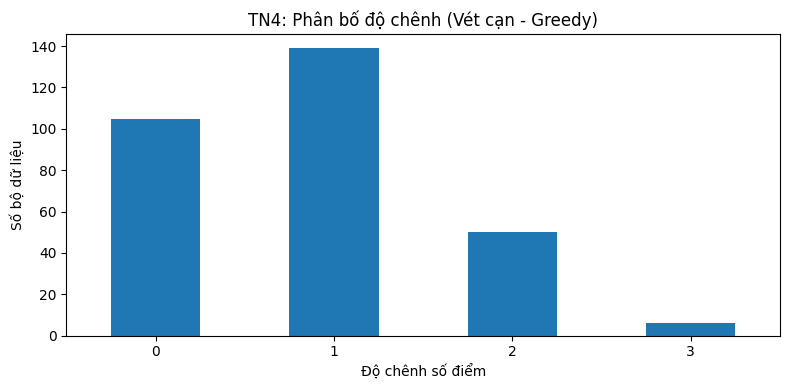

In [6]:
# Biểu đồ phân bố độ chênh: số điểm vét cạn trừ số điểm Greedy.
gap_counts = random_df["gap_brute_minus_greedy"].value_counts().sort_index()
ax = gap_counts.plot(kind="bar", figsize=(8, 4))
ax.set_title("TN4: Phân bố độ chênh (Vét cạn - Greedy)")
ax.set_xlabel("Độ chênh số điểm")
ax.set_ylabel("Số bộ dữ liệu")
ax.set_xticklabels([str(x) for x in gap_counts.index], rotation=0)
plt.tight_layout()
plt.show()

## 4. Kiểm tra điều kiện nghiệm thu

Không chỉnh số liệu để ép kết quả đạt kỳ vọng. Nếu điều kiện nào không đạt, cần kiểm tra dữ liệu và thuật toán rồi chạy lại.

In [7]:
tn2 = fixed_df[fixed_df["scenario"] == "TN2"].set_index("algorithm")
tn2_greedy = int(tn2.loc["Greedy", "num_visited"])
tn2_astar = int(tn2.loc["A*", "num_visited"])
tn2_brute = int(tn2.loc["Vet can", "num_visited"])

checks = {
    "A* bằng vét cạn ở mọi kịch bản TN1-TN3": bool((count_pivot["A*"] == count_pivot["Vet can"]).all()),
    "Vét cạn không kém Greedy ở TN1-TN3": bool((count_pivot["Vet can"] >= count_pivot["Greedy"]).all()),
    "TN2: Greedy ít hơn A* ít nhất 1 điểm": tn2_greedy < tn2_astar,
    "TN4: A* khác vét cạn bằng 0 bộ": random_summary["astar_differs_from_brute"] == 0,
}
for label, passed in checks.items():
    print(("ĐẠT" if passed else "CHƯA ĐẠT") + " — " + label)

if not checks["TN2: Greedy ít hơn A* ít nhất 1 điểm"]:
    print("\nLưu ý: với bộ dữ liệu hiện tại trong file IDEA, TN2 có thể cho Greedy bằng A* về số điểm. Không tự sửa kết quả; nhóm cần kiểm tra lại ma trận/giờ mở đóng cửa từ dữ liệu thực tế để tạo đúng kịch bản bẫy.")

ĐẠT — A* bằng vét cạn ở mọi kịch bản TN1-TN3
ĐẠT — Vét cạn không kém Greedy ở TN1-TN3
ĐẠT — TN2: Greedy ít hơn A* ít nhất 1 điểm
ĐẠT — TN4: A* khác vét cạn bằng 0 bộ


In [8]:
print("Các file kết quả:")
for file in sorted(OUTPUT_DIR.glob("*.csv")):
    print("-", file.name)

Các file kết quả:
- fixed_scenarios_results.csv
- TN4_random_300_results.csv
- TN4_summary.csv
